# Практическая работа №3. Сборка пайплайна предобработки

**Уровень B.** Датасет IBM Telco Customer Churn.

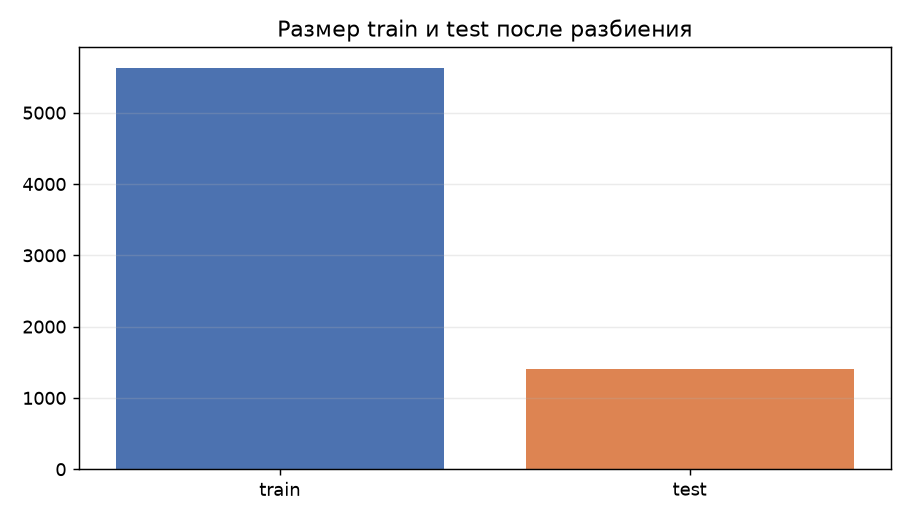

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
df=pd.read_csv("data/Telco-Customer-Churn.csv")
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce")
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
X=df.drop(columns="Churn"); y=df.Churn.map({"Yes":1,"No":0}); Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.2,stratify=y,random_state=42)
num=X.select_dtypes(include=np.number).columns; cat=X.select_dtypes(exclude=np.number).columns
pre=ColumnTransformer([("num",Pipeline([("imp",SimpleImputer(strategy="median")),("scale",StandardScaler())]),num),("cat",Pipeline([("imp",SimpleImputer(strategy="most_frequent")),("oh",OneHotEncoder(handle_unknown="ignore"))]),cat)])
A=pre.fit_transform(Xtr); B=pre.transform(Xte); print(A.shape,B.shape)

### Вывод

Результаты представлены таблицами и графиками выше. Обработка данных выполняется воспроизводимо с фиксированным `random_state=42`.